
# Notebook 8: Feature Scaling

## Objective
Understand why feature scaling is important and how different
scaling techniques transform numerical features.

## Learning Outcomes
- Understand scale-sensitive and scale-insensitive algorithms.
- Compare normalization and standardization.
- Apply Min-Max, Standard, Robust, and MaxAbs scaling.
- Understand how outliers affect scaling.
- Select an appropriate scaling method for a machine learning task.


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.preprocessing import (
    StandardScaler,
    MinMaxScaler,
    RobustScaler,
    MaxAbsScaler,
    Normalizer
)

print("Libraries imported successfully!")

Libraries imported successfully!


In [2]:
data = {
    "Age": [22, 25, 30, 35, 40, 45, 50, 55],
    "Salary": [20000, 25000, 30000, 40000, 50000, 60000, 75000, 300000],
    "Experience": [1, 2, 5, 8, 10, 12, 15, 20]
}

df_scaling = pd.DataFrame(data)

print("Original dataset:")
display(df_scaling)

print("\nDescriptive statistics:")
display(df_scaling.describe())

Original dataset:


,Age,Salary,Experience
0,22,20000,1
1,25,25000,2
2,30,30000,5
3,35,40000,8
4,40,50000,10
5,45,60000,12
6,50,75000,15
7,55,300000,20



Descriptive statistics:


,Age,Salary,Experience
count,8.00000,8.000000,8.000000
mean,37.75000,75000.000000,9.125000
std,11.85327,92774.688666,6.512351
min,22.00000,20000.000000,1.000000
25%,28.75000,28750.000000,4.250000
50%,37.50000,45000.000000,9.000000
75%,46.25000,63750.000000,12.750000
max,55.00000,300000.000000,20.000000



## 1. Why Feature Scaling?

Feature scaling transforms numerical features to comparable
scales without necessarily changing the underlying relationships.

For example, age may range from 20 to 60, while salary may range
from 20,000 to 300,000.

Features with large numerical ranges can dominate distance
calculations and optimization in some machine learning algorithms.

Scaling can improve optimization, numerical stability, and
model performance for algorithms that are sensitive to feature scale.



## 2. Scale-Sensitive Algorithms

Examples include:
- K-Nearest Neighbors (KNN)
- K-Means clustering
- Support Vector Machines (especially RBF kernels)
- Logistic and linear regression with regularization
- Principal Component Analysis (PCA)
- Neural networks trained with gradient-based optimization

These algorithms may be affected by differences in feature scales.

## 3. Scale-Insensitive Algorithms

Tree-based algorithms, such as decision trees and random forests,
are generally much less sensitive to monotonic feature scaling.

Gradient-boosted trees are also usually scale-insensitive.

Scaling may still be useful in a broader preprocessing pipeline,
but it is not always necessary for these models.


In [3]:
normalizer = Normalizer(norm="l2")

normalized_values = normalizer.fit_transform(
    df_scaling[["Age", "Salary", "Experience"]]
)

df_normalized = pd.DataFrame(
    normalized_values,
    columns=["Age", "Salary", "Experience"]
)

print("L2-normalized data:")
display(df_normalized)

L2-normalized data:


,Age,Salary,Experience
0,0.001100,0.999999,0.000050
1,0.001000,0.999999,0.000080
2,0.001000,0.999999,0.000167
3,0.000875,1.000000,0.000200
4,0.000800,1.000000,0.000200
5,0.000750,1.000000,0.000200
6,0.000667,1.000000,0.000200
7,0.000183,1.000000,0.000067


In [4]:
standard_scaler = StandardScaler()

standard_values = standard_scaler.fit_transform(df_scaling)

df_standard = pd.DataFrame(
    standard_values,
    columns=df_scaling.columns
)

print("Standardized data:")
display(df_standard)

print("\nMeans after scaling:")
print(df_standard.mean().round(3))

print("\nStandard deviations after scaling:")
print(df_standard.std(ddof=0).round(3))

Standardized data:


,Age,Salary,Experience
0,-1.420491,-0.633766,-1.333772
1,-1.149921,-0.576151,-1.169615
2,-0.698972,-0.518536,-0.677146
3,-0.248022,-0.403306,-0.184676
4,0.202927,-0.288076,0.143637
5,0.653877,-0.172845,0.471950
6,1.104826,0.000000,0.964420
7,1.555775,2.592680,1.785202



Means after scaling:
Age           0.0
Salary        0.0
Experience    0.0
dtype: float64

Standard deviations after scaling:
Age           1.0
Salary        1.0
Experience    1.0
dtype: float64


In [5]:
minmax_scaler = MinMaxScaler()

minmax_values = minmax_scaler.fit_transform(df_scaling)

df_minmax = pd.DataFrame(
    minmax_values,
    columns=df_scaling.columns
)

print("Min-Max scaled data:")
display(df_minmax)

print("\nColumn minimums:")
print(df_minmax.min())

print("\nColumn maximums:")
print(df_minmax.max())

Min-Max scaled data:


,Age,Salary,Experience
0,0.000000,0.000000,0.000000
1,0.090909,0.017857,0.052632
2,0.242424,0.035714,0.210526
3,0.393939,0.071429,0.368421
4,0.545455,0.107143,0.473684
5,0.696970,0.142857,0.578947
6,0.848485,0.196429,0.736842
7,1.000000,1.000000,1.000000



Column minimums:
Age           0.0
Salary        0.0
Experience    0.0
dtype: float64

Column maximums:
Age           1.0
Salary        1.0
Experience    1.0
dtype: float64


In [6]:
robust_scaler = RobustScaler()

robust_values = robust_scaler.fit_transform(df_scaling)

df_robust = pd.DataFrame(
    robust_values,
    columns=df_scaling.columns
)

print("Robust-scaled data:")
display(df_robust)

print("\nMedians after scaling:")
print(df_robust.median())

Robust-scaled data:


,Age,Salary,Experience
0,-0.885714,-0.714286,-0.941176
1,-0.714286,-0.571429,-0.823529
2,-0.428571,-0.428571,-0.470588
3,-0.142857,-0.142857,-0.117647
4,0.142857,0.142857,0.117647
5,0.428571,0.428571,0.352941
6,0.714286,0.857143,0.705882
7,1.000000,7.285714,1.294118



Medians after scaling:
Age           0.0
Salary        0.0
Experience    0.0
dtype: float64


In [7]:
maxabs_scaler = MaxAbsScaler()

maxabs_values = maxabs_scaler.fit_transform(df_scaling)

df_maxabs = pd.DataFrame(
    maxabs_values,
    columns=df_scaling.columns
)

print("MaxAbs-scaled data:")
display(df_maxabs)

print("\nMaximum absolute value in each column:")
print(df_maxabs.abs().max())

MaxAbs-scaled data:


,Age,Salary,Experience
0,0.400000,0.066667,0.05
1,0.454545,0.083333,0.10
2,0.545455,0.100000,0.25
3,0.636364,0.133333,0.40
4,0.727273,0.166667,0.50
5,0.818182,0.200000,0.60
6,0.909091,0.250000,0.75
7,1.000000,1.000000,1.00



Maximum absolute value in each column:
Age           1.0
Salary        1.0
Experience    1.0
dtype: float64


In [8]:
comparison = pd.DataFrame({
    "Original_Salary": df_scaling["Salary"],
    "StandardScaler": df_standard["Salary"],
    "MinMaxScaler": df_minmax["Salary"],
    "RobustScaler": df_robust["Salary"],
    "MaxAbsScaler": df_maxabs["Salary"],
})

display(comparison.round(3))

,Original_Salary,StandardScaler,MinMaxScaler,RobustScaler,MaxAbsScaler
0,20000,-0.634,0.000,-0.714,0.067
1,25000,-0.576,0.018,-0.571,0.083
2,30000,-0.519,0.036,-0.429,0.100
3,40000,-0.403,0.071,-0.143,0.133
4,50000,-0.288,0.107,0.143,0.167
5,60000,-0.173,0.143,0.429,0.200
6,75000,0.000,0.196,0.857,0.250
7,300000,2.593,1.000,7.286,1.000


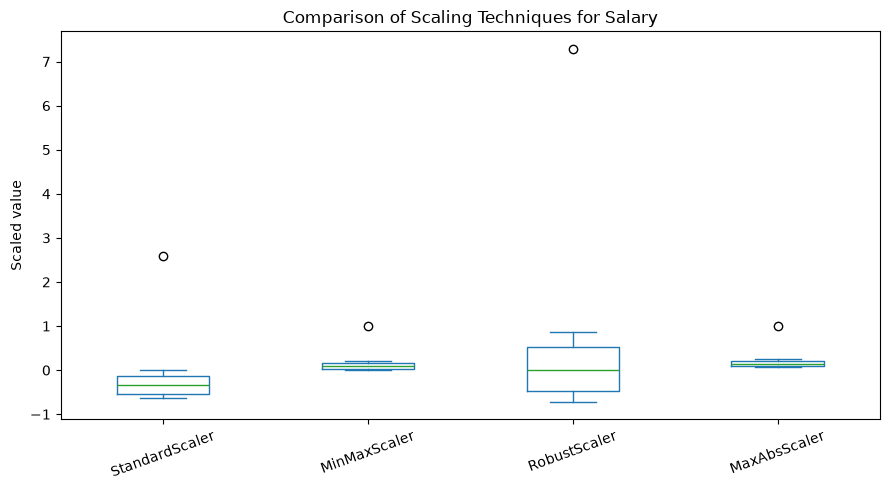

In [9]:
comparison_to_plot = comparison.drop(columns=["Original_Salary"])

comparison_to_plot.plot(
    kind="box",
    figsize=(9, 5)
)

plt.title("Comparison of Scaling Techniques for Salary")
plt.ylabel("Scaled value")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()


## 4. How Outliers Affect Scaling

### StandardScaler
Outliers can shift the mean and increase the standard deviation,
compressing ordinary observations toward zero.

### MinMaxScaler
An extreme minimum or maximum can cause most observations to
occupy a narrow interval within the scaled range.

### RobustScaler
Uses the median and interquartile range, so extreme values
usually have less influence on the fitted scaling parameters.

### MaxAbsScaler
An extreme absolute value increases the denominator and can
compress the remaining observations.

### Normalization
Each row is scaled independently to a chosen vector norm.
Large features can dominate a row's direction before normalization.

Outliers should be investigated separately. Scaling changes
feature magnitudes; it does not establish whether an observation
is valid or erroneous.


In [10]:
from sklearn.model_selection import train_test_split

X = df_scaling[["Age", "Salary", "Experience"]]

X_train, X_test = train_test_split(
    X,
    test_size=0.25,
    random_state=42
)

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Training shape:", X_train_scaled.shape)
print("Testing shape:", X_test_scaled.shape)

Training shape: (6, 3)
Testing shape: (2, 3)



## 5. Summary of Scaling Techniques

| Technique | Method | Main advantage | Main limitation |
|---|---|---|---|
| StandardScaler | Mean and standard deviation | Common, centered scale | Sensitive to outliers |
| MinMaxScaler | Minimum and maximum | Fixed fitted range | Sensitive to extremes |
| RobustScaler | Median and IQR | More robust to outliers | No fixed output range |
| MaxAbsScaler | Maximum absolute value | Preserves zero and sparse structure | Sensitive to extremes |
| Normalizer | Row-wise vector norm | Useful for vector similarity | Changes row magnitudes |

Choose the method based on the algorithm, feature distribution,
presence of outliers, and meaning of the data.



## Conclusion

In this notebook, I learned why feature scaling is important
and compared scale-sensitive and scale-insensitive algorithms.

I practiced normalization, standardization, Min-Max scaling,
RobustScaler, and MaxAbsScaler.

I observed how outliers affect different scaling methods and
learned that RobustScaler is often less sensitive to extreme
values because it uses the median and interquartile range.

Finally, I learned to fit scalers on training data only to avoid
data leakage during machine learning model development.
